In [1]:
import pandas as pd

df = pd.read_csv("dataset_seperation5652.csv")
df.head()


,Dst Port,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,63409.0,17.0,10435.0,14.0,1.0,12152.0,868.0,868.0,868.0,868.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,attack_booters
1,27550.0,17.0,1496.0,7.0,1.0,10304.0,1472.0,1472.0,1472.0,1472.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,attack_booters
2,28863.0,17.0,5598.0,24.0,1.0,24624.0,1026.0,1026.0,1026.0,1026.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,attack_booters
3,21123.0,17.0,23584.0,21.0,1.0,18228.0,868.0,868.0,868.0,868.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,attack_booters
4,23437.0,17.0,6590.0,24.0,1.0,20832.0,868.0,868.0,868.0,868.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,attack_booters


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56520 entries, 0 to 56519
Data columns (total 79 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Dst Port           56520 non-null  float64
 1   Protocol           56520 non-null  float64
 2   Flow Duration      56520 non-null  float64
 3   Tot Fwd Pkts       56520 non-null  float64
 4   Tot Bwd Pkts       56520 non-null  float64
 5   TotLen Fwd Pkts    56520 non-null  float64
 6   TotLen Bwd Pkts    56520 non-null  float64
 7   Fwd Pkt Len Max    56520 non-null  float64
 8   Fwd Pkt Len Min    56520 non-null  float64
 9   Fwd Pkt Len Mean   56520 non-null  float64
 10  Fwd Pkt Len Std    56520 non-null  float64
 11  Bwd Pkt Len Max    56520 non-null  float64
 12  Bwd Pkt Len Min    56520 non-null  float64
 13  Bwd Pkt Len Mean   56520 non-null  float64
 14  Bwd Pkt Len Std    56520 non-null  float64
 15  Flow Byts/s        56520 non-null  float64
 16  Flow Pkts/s        565

In [3]:
df['Label'].value_counts()

Label
attack_booters          5652
attack_botiot           5652
attack_caida            5652
attack_cicddos2019      5652
attack_cicids2017       5652
attack_csecicids2018    5652
attack_ctu              5652
benign_cicddos2019      5652
benign_cicids2017       5652
benign_csecicids2018    5652
Name: count, dtype: int64

In [4]:
df.columns = df.columns.str.strip().str.lower()

df.columns = df.columns.str.replace(' ', '_', regex=False)
df.columns = df.columns.str.replace('/', '_', regex=False)
df.columns = df.columns.str.replace('.', '_', regex=False)

print("First 10 standardized columns: ")
print(df.columns[:10].tolist())

label_col = [col for col in df.columns if 'label' in col]
print(f"\nLabel column found: {label_col}")

First 10 standardized columns: 
['dst_port', 'protocol', 'flow_duration', 'tot_fwd_pkts', 'tot_bwd_pkts', 'totlen_fwd_pkts', 'totlen_bwd_pkts', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean']

Label column found: ['label']


In [5]:
df.shape

(56520, 79)

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.groupby("label", dropna=False).apply(
    lambda x: x.duplicated().sum()
)

C:\Users\HP\AppData\Local\Temp\ipykernel_3344\3142294550.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("label", dropna=False).apply(


label
attack_booters          0
attack_botiot           0
attack_caida            0
attack_cicddos2019      0
attack_cicids2017       0
attack_csecicids2018    0
attack_ctu              0
benign_cicddos2019      0
benign_cicids2017       0
benign_csecicids2018    0
dtype: int64

In [8]:
# df.drop_duplicates(inplace=True)

In [9]:
# df['label'].value_counts()

In [10]:
# df.groupby("label", dropna=False).apply(
#     lambda x: x.duplicated().sum()
# )

In [8]:
print(df.isna().sum().sum())

0


In [9]:
import numpy as np
np.isinf(df.select_dtypes(include=[np.number])).values.sum()

np.int64(0)

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report,
confusion_matrix, accuracy_score, roc_curve, auc, matthews_corrcoef)
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [11]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['label'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [12]:
X_train.shape

(45216, 78)

In [13]:
X_test.shape

(11304, 78)

In [14]:
y_train.shape, y_train.value_counts()

((45216,),
 label
 attack_botiot           4522
 benign_cicddos2019      4522
 benign_cicids2017       4522
 attack_csecicids2018    4522
 attack_booters          4522
 attack_caida            4522
 attack_cicddos2019      4521
 attack_ctu              4521
 attack_cicids2017       4521
 benign_csecicids2018    4521
 Name: count, dtype: int64)

In [15]:
y_test.value_counts()

label
attack_ctu              1131
attack_cicids2017       1131
attack_cicddos2019      1131
benign_csecicids2018    1131
attack_caida            1130
attack_botiot           1130
benign_cicddos2019      1130
attack_booters          1130
benign_cicids2017       1130
attack_csecicids2018    1130
Name: count, dtype: int64

In [16]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.dtype, X_train_scaled.shape, X_train_scaled.min(), X_train_scaled.max())

float64 (45216, 78) 0.0 1.0000000000000002


In [17]:
X_train_scaled.shape, X_test_scaled.shape

((45216, 78), (11304, 78))

In [21]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,           
    min_samples_split=250,
    min_samples_leaf=100,
    class_weight='balanced', 
    max_samples=0.75,
    oob_score=True,           
    n_jobs=-1,            
    random_state=42,
    verbose=1
)
rf.fit(X_train_scaled, y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    1.2s finished


RandomForestClassifier(class_weight='balanced', max_depth=10, max_samples=0.75,
                       min_samples_leaf=100, min_samples_split=250, n_jobs=-1,
                       oob_score=True, random_state=42, verbose=1)

In [22]:
target_names = rf.classes_.tolist()
target_names

['attack_booters',
 'attack_botiot',
 'attack_caida',
 'attack_cicddos2019',
 'attack_cicids2017',
 'attack_csecicids2018',
 'attack_ctu',
 'benign_cicddos2019',
 'benign_cicids2017',
 'benign_csecicids2018']

In [23]:
joblib.dump(rf, "RF_classifier.pkl")
print("Model saved!")

train_preds = rf.predict(X_train_scaled)
test_preds = rf.predict(X_test_scaled)
test_probs = rf.predict_proba(X_test_scaled)

train_acc = accuracy_score(y_train, train_preds)
test_acc = accuracy_score(y_test, test_preds)

print("\n --- OVERFITTING DIAGNOSTICS ---")
print(f"Training Accuracy: {train_acc:.5f}")
print(f"Testing Accuracy: {test_acc: .5f}")


print(f"Matthews Correlation Coefficient (MCC): {matthews_corrcoef(y_test, test_preds):.5f}")
print("\nclassification Report: ")
print(classification_report(y_test, test_preds, target_names=target_names))


Model saved!


[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.0s finished



 --- OVERFITTING DIAGNOSTICS ---
Training Accuracy: 0.92452
Testing Accuracy:  0.92427
Matthews Correlation Coefficient (MCC): 0.91603

classification Report: 
                      precision    recall  f1-score   support

      attack_booters       0.98      0.99      0.99      1130
       attack_botiot       0.98      0.98      0.98      1130
        attack_caida       1.00      1.00      1.00      1130
  attack_cicddos2019       0.96      0.97      0.96      1131
   attack_cicids2017       0.93      0.91      0.92      1131
attack_csecicids2018       0.89      0.87      0.88      1130
          attack_ctu       0.95      0.96      0.96      1131
  benign_cicddos2019       0.90      0.96      0.93      1130
   benign_cicids2017       0.86      0.74      0.79      1130
benign_csecicids2018       0.80      0.87      0.83      1131

            accuracy                           0.92     11304
           macro avg       0.92      0.92      0.92     11304
        weighted avg       0.92

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.0s finished


[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.0s finished


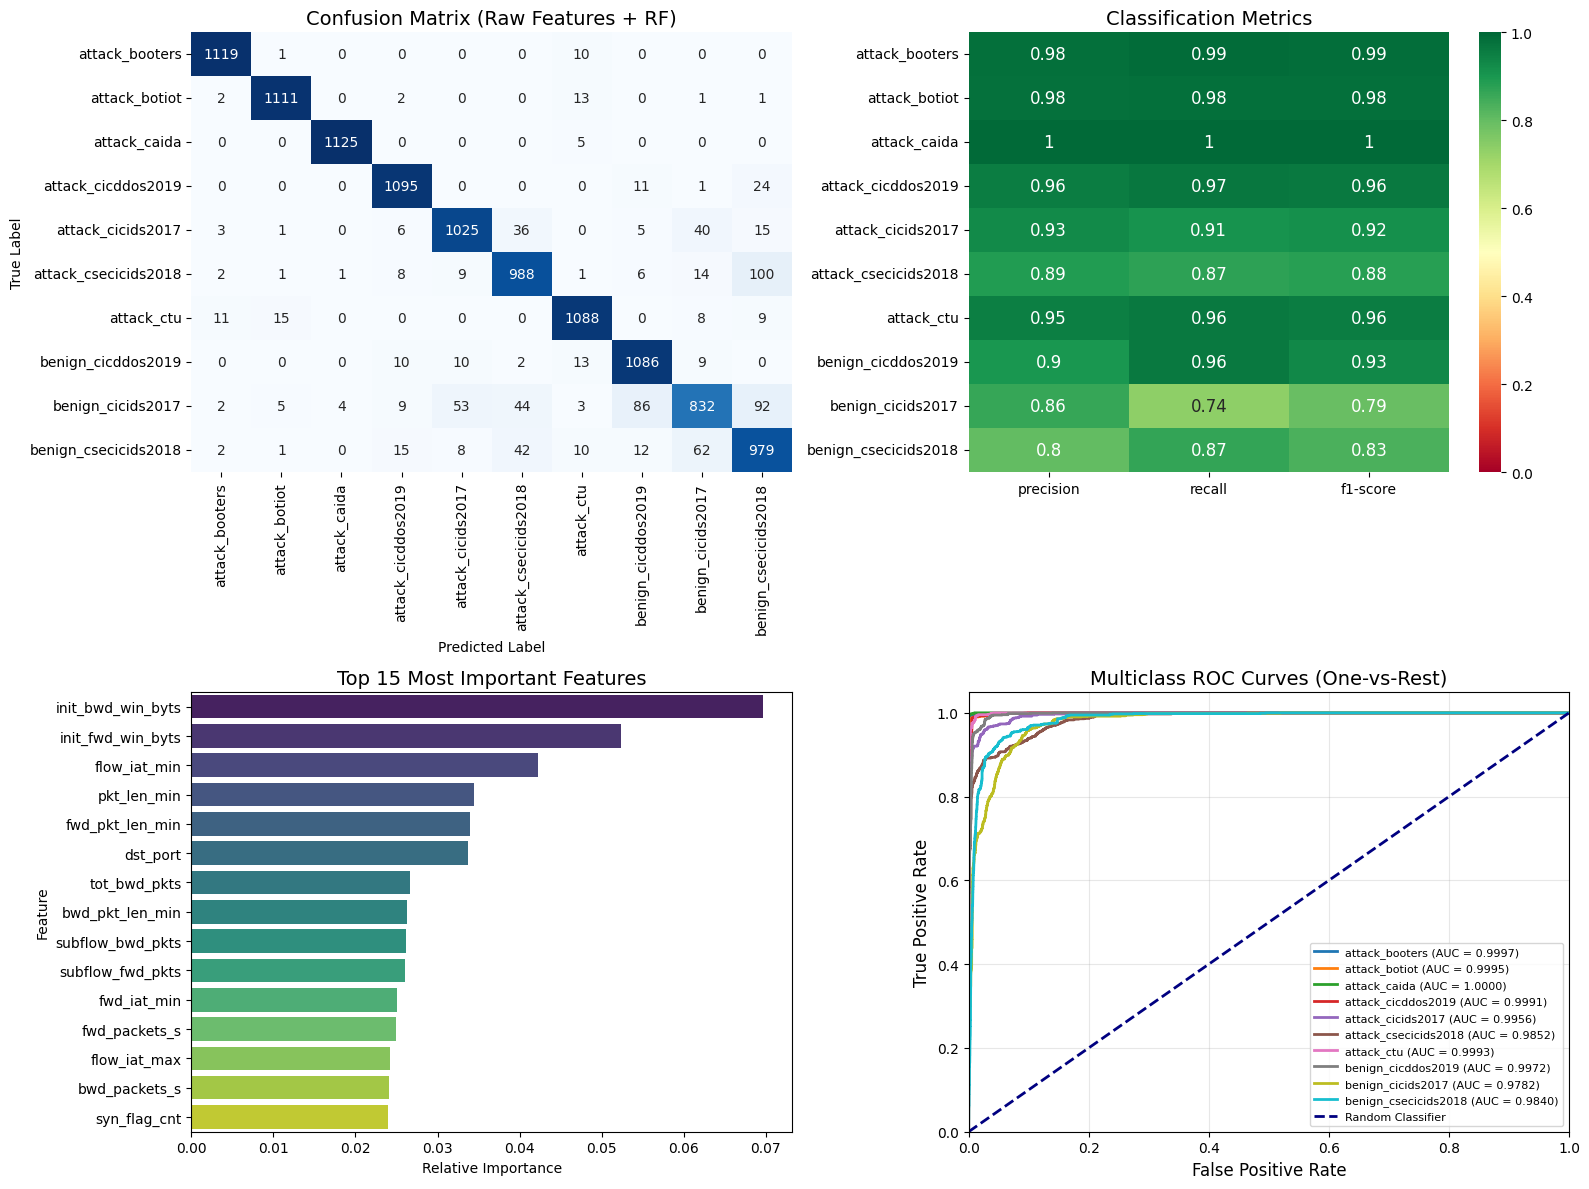

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import LabelEncoder

plt.figure(figsize=(16, 12))

# 1. Confusion Matrix
plt.subplot(2, 2, 1)

cm = confusion_matrix(y_test, test_preds)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=target_names,
    yticklabels=target_names
)

plt.title('Confusion Matrix (Raw Features + RF)', fontsize=14)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')


# 2. Classification Metrics
plt.subplot(2, 2, 2)

report_dict = classification_report(
    y_test,
    test_preds,
    target_names=target_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).iloc[:-1, :len(target_names)].T

sns.heatmap(
    report_df,
    annot=True,
    cmap='RdYlGn',
    cbar=True,
    annot_kws={"size": 12},
    vmin=0,
    vmax=1
)

plt.title('Classification Metrics', fontsize=14)


# 3. Feature Importance
plt.subplot(2, 2, 3)

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1][:15]

try:
    actual_feature_names = scaler.feature_names_in_
    top_features = [actual_feature_names[i] for i in indices]
except AttributeError:
    top_features = [f"Feature{i}" for i in indices]

sns.barplot(
    x=importances[indices],
    y=top_features,
    hue=top_features,
    palette="viridis",
    legend=False
)

plt.title('Top 15 Most Important Features', fontsize=14)
plt.xlabel('Relative Importance')
plt.ylabel('Feature')


# 4. Multiclass ROC Curve (One-vs-Rest)
plt.subplot(2, 2, 4)

# Use the exact class order associated with predict_proba()
classes = rf.classes_

# Binarize the true labels using the model's class order
y_test_bin = label_binarize(y_test, classes=classes)

# For binary classification, label_binarize returns one column.
# Multiclass ROC needs one binary target per class.
if len(classes) == 2:
    y_test_bin = np.column_stack([
        1 - y_test_bin[:, 0],
        y_test_bin[:, 0]
    ])

# Predicted probabilities: one column per class
test_probs = rf.predict_proba(X_test_scaled)

for i, class_name in enumerate(classes):

    # ROC cannot be calculated if the test set lacks positives
    # or negatives for this class.
    if len(np.unique(y_test_bin[:, i])) < 2:
        print(f"Skipping ROC for class {class_name}: "
              "test set needs positive and negative examples.")
        continue

    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        test_probs[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f'{class_name} (AUC = {roc_auc:.4f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    color='navy',
    lw=2,
    linestyle='--',
    label='Random Classifier'
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Multiclass ROC Curves (One-vs-Rest)', fontsize=14)
plt.legend(loc='lower right', fontsize=8)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.0s finished


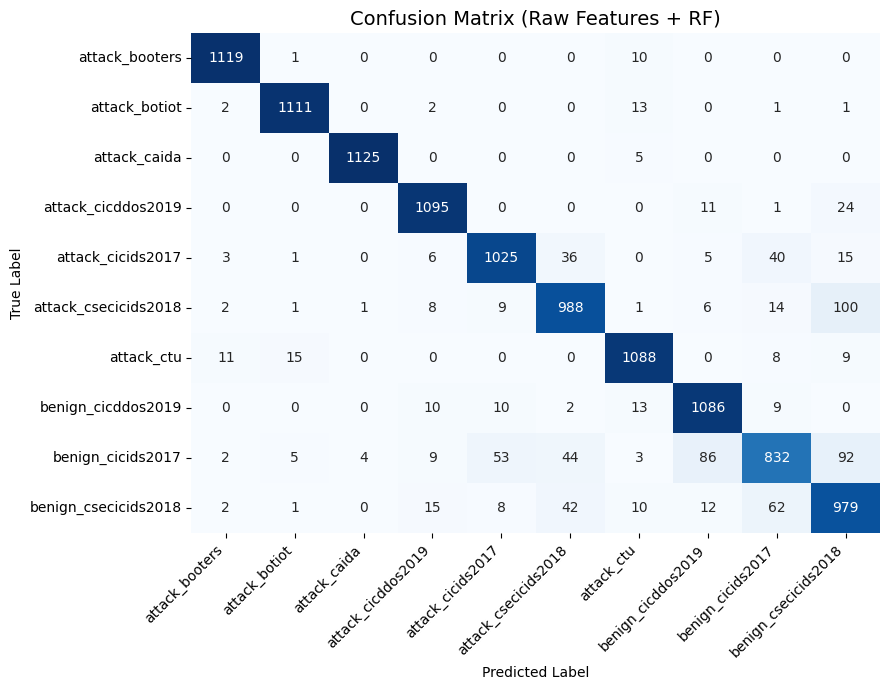

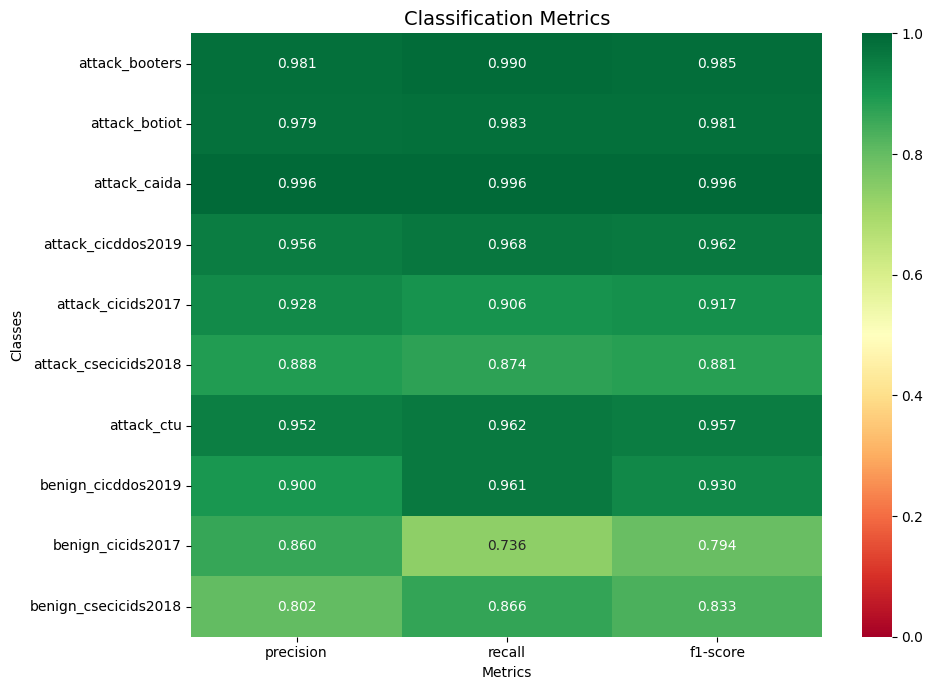

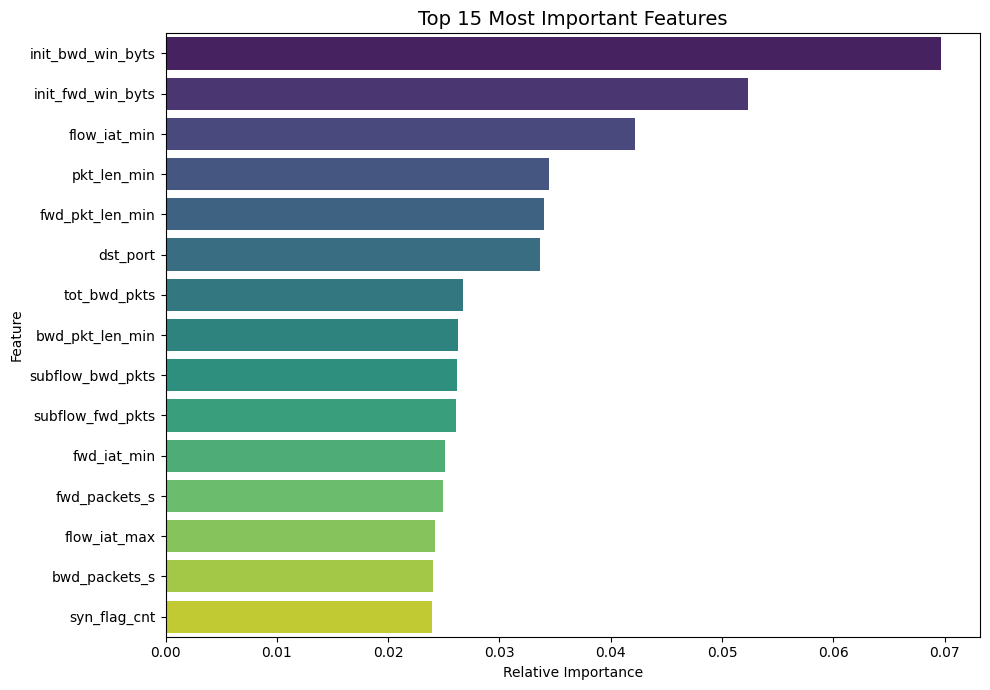

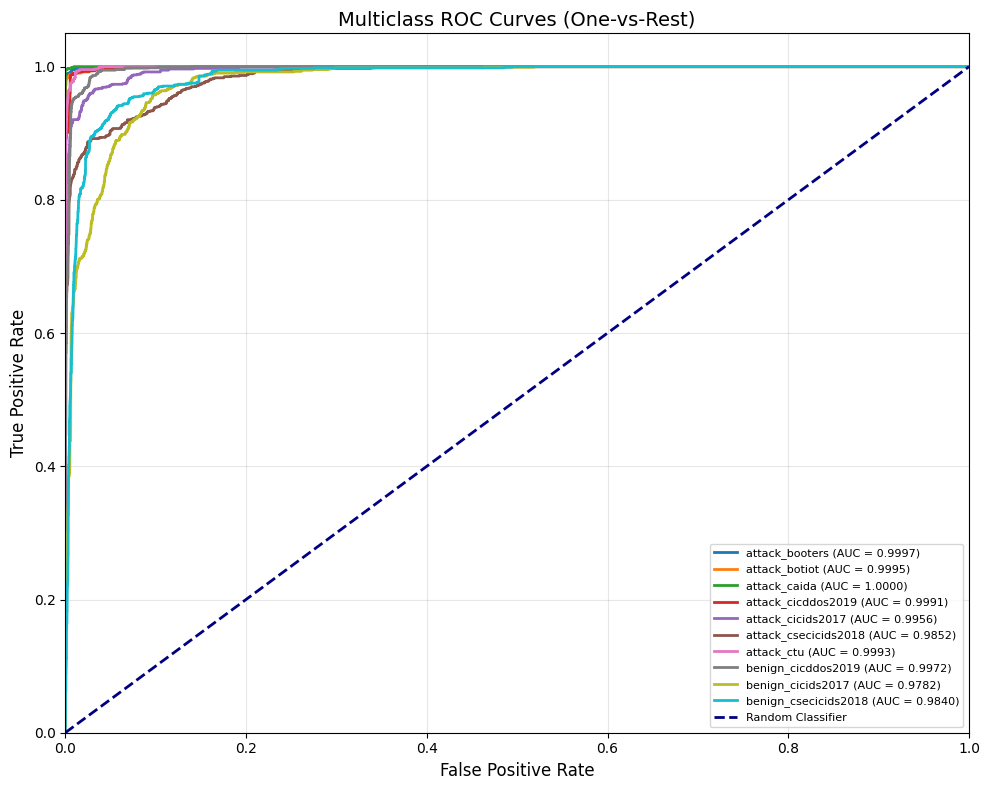

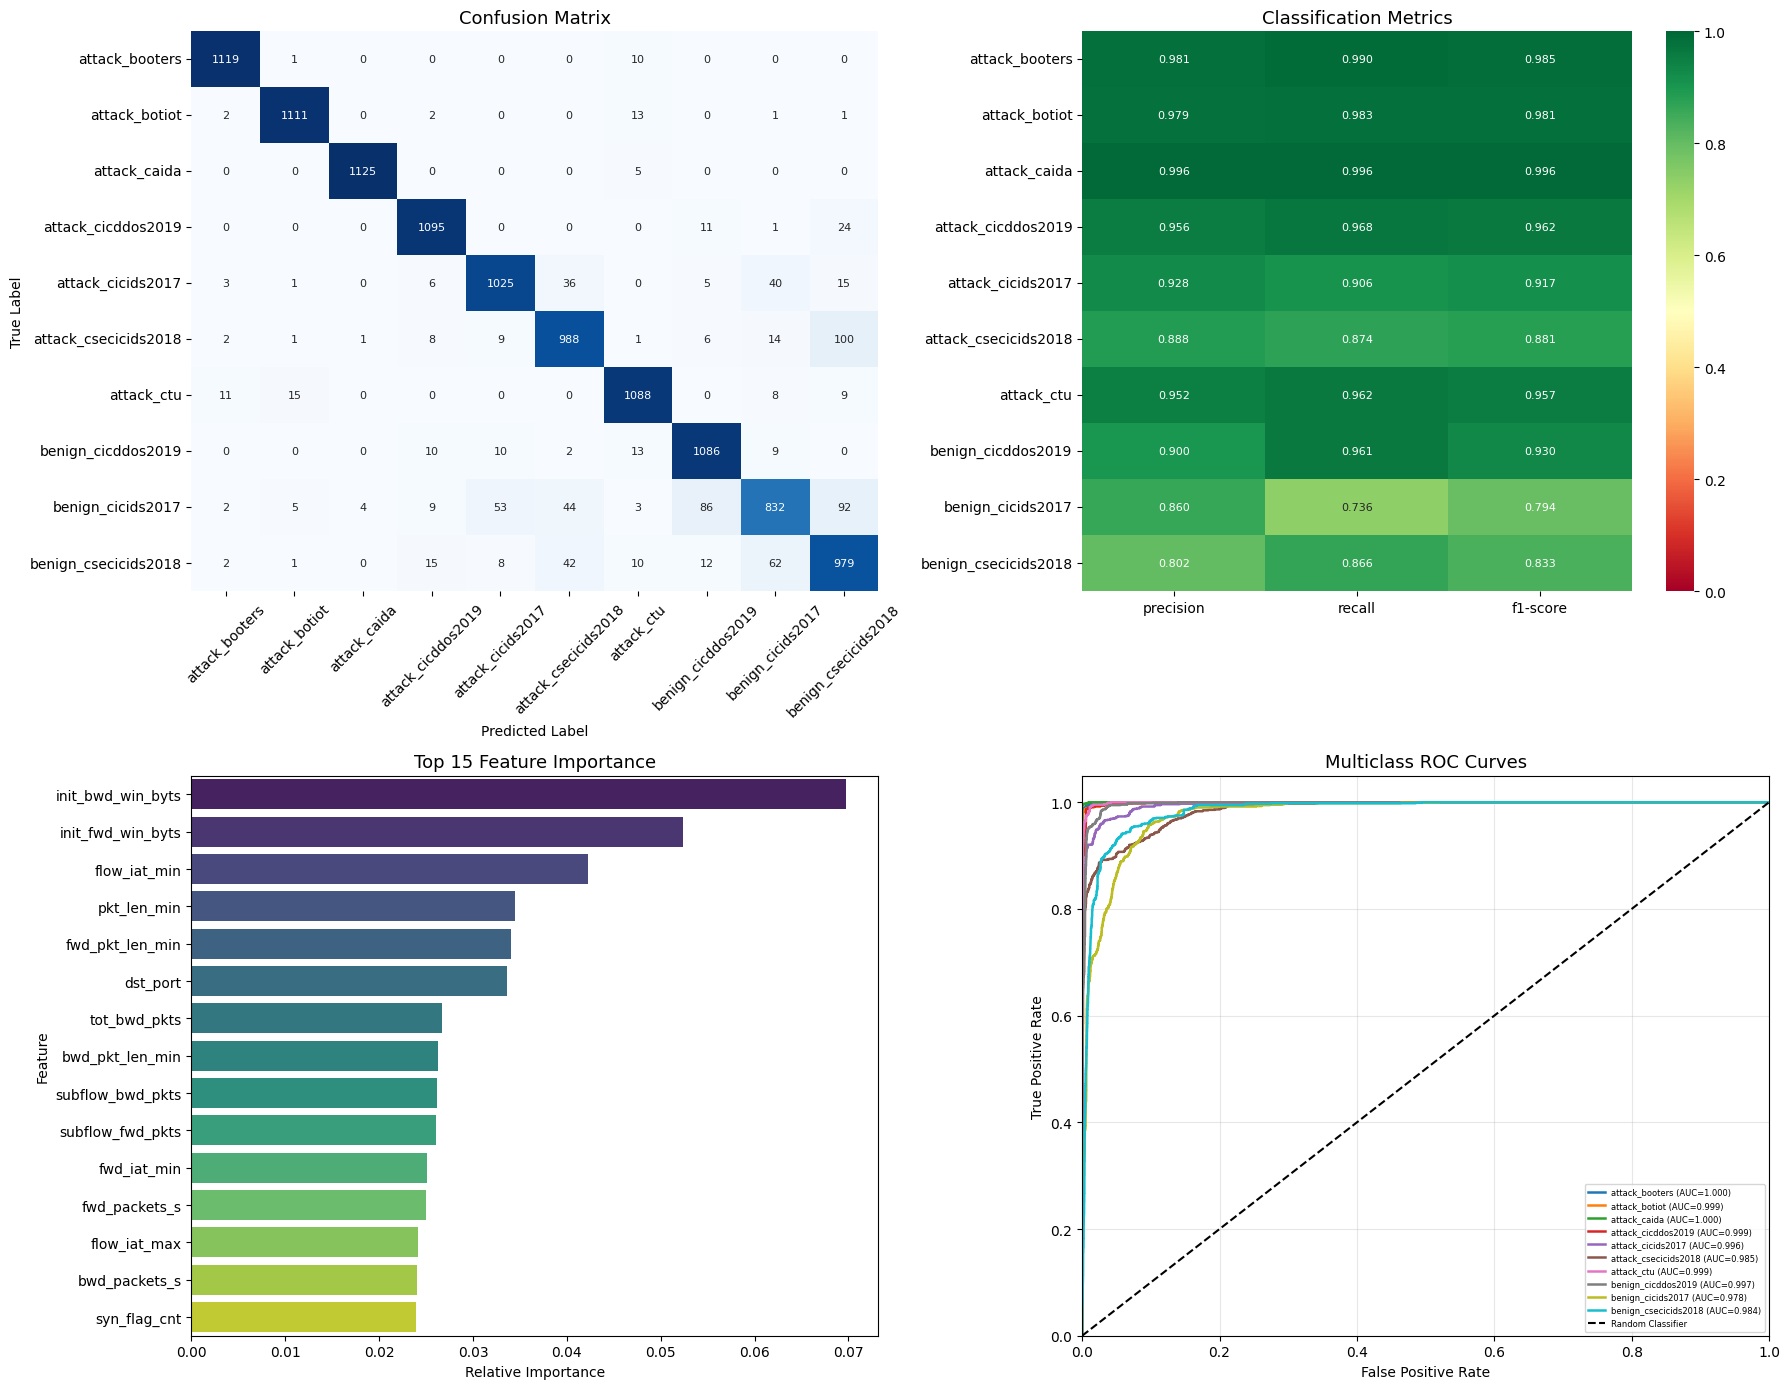


All plots saved successfully!
Folder: D:\7th_sem_MinorProject_SystemSecurity\GitHub\TSNE\RF_for_sepration_test\Random_Forest_Plots_5652

Saved image files:
 - 01_confusion_matrix.png
 - 02_classification_metrics.png
 - 03_feature_importance.png
 - 04_multiclass_roc_curve.png
 - 05_all_plots_combined.png


In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

# ------------------------------------------------------------
# 1. CREATE OUTPUT FOLDER
# ------------------------------------------------------------

save_dir = "Random_Forest_Plots_5652"
os.makedirs(save_dir, exist_ok=True)

# Get model classes in the correct probability-column order
classes = np.asarray(rf.classes_)

# Ensure predictions and class labels use the same representation
test_preds = np.asarray(test_preds)
y_test_array = np.asarray(y_test)

# Predicted probability for every class
test_probs = rf.predict_proba(X_test_scaled)

# Ensure class names match the model classes
# Assumes target_names follows the same order as rf.classes_
if len(target_names) != len(classes):
    raise ValueError(
        f"Number of target_names ({len(target_names)}) must match "
        f"number of model classes ({len(classes)})."
    )

# Mapping between actual labels and display names
class_name_map = dict(zip(classes.tolist(), target_names))

# Use the actual class labels for all classification metrics
cm = confusion_matrix(
    y_test_array,
    test_preds,
    labels=classes
)

report_dict = classification_report(
    y_test_array,
    test_preds,
    labels=classes,
    target_names=target_names,
    output_dict=True,
    zero_division=0
)

# Correct orientation: rows = classes, columns = metrics
report_df = pd.DataFrame(report_dict).T
report_df = report_df.loc[
    target_names,
    ["precision", "recall", "f1-score"]
]

# Feature importance
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1][:15]

try:
    feature_names = list(scaler.feature_names_in_)
    top_features = [feature_names[i] for i in indices]
except AttributeError:
    top_features = [f"Feature {i}" for i in indices]

# ------------------------------------------------------------
# 2. PREPARE MULTICLASS ROC DATA
# ------------------------------------------------------------

y_test_bin = label_binarize(
    y_test_array,
    classes=classes
)

# Binary classification needs two ROC columns
if len(classes) == 2:
    y_test_bin = np.column_stack(
        [1 - y_test_bin[:, 0], y_test_bin[:, 0]]
    )

# ------------------------------------------------------------
# 3. PLOT 1: CONFUSION MATRIX
# ------------------------------------------------------------

fig1, ax1 = plt.subplots(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=target_names,
    yticklabels=target_names,
    ax=ax1
)

ax1.set_title("Confusion Matrix (Raw Features + RF)", fontsize=14)
ax1.set_xlabel("Predicted Label")
ax1.set_ylabel("True Label")
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax1.get_yticklabels(), rotation=0)

fig1.tight_layout()
fig1.savefig(
    os.path.join(save_dir, "01_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 4. PLOT 2: CLASSIFICATION METRICS
# ------------------------------------------------------------

fig2, ax2 = plt.subplots(figsize=(10, 7))

sns.heatmap(
    report_df,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    cbar=True,
    annot_kws={"size": 10},
    ax=ax2
)

ax2.set_title("Classification Metrics", fontsize=14)
ax2.set_xlabel("Metrics")
ax2.set_ylabel("Classes")

fig2.tight_layout()
fig2.savefig(
    os.path.join(save_dir, "02_classification_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 5. PLOT 3: TOP 15 FEATURE IMPORTANCE
# ------------------------------------------------------------

fig3, ax3 = plt.subplots(figsize=(10, 7))

sns.barplot(
    x=importances[indices],
    y=top_features,
    hue=top_features,
    palette="viridis",
    legend=False,
    ax=ax3
)

ax3.set_title("Top 15 Most Important Features", fontsize=14)
ax3.set_xlabel("Relative Importance")
ax3.set_ylabel("Feature")

fig3.tight_layout()
fig3.savefig(
    os.path.join(save_dir, "03_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 6. PLOT 4: MULTICLASS ROC CURVES (ONE-VS-REST)
# ------------------------------------------------------------

fig4, ax4 = plt.subplots(figsize=(10, 8))

for i, class_label in enumerate(classes):

    # ROC requires both positive and negative examples
    if len(np.unique(y_test_bin[:, i])) < 2:
        print(
            f"Skipping ROC for {class_name_map[class_label]}: "
            "test set needs both positive and negative examples."
        )
        continue

    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        test_probs[:, i]
    )

    roc_auc = auc(fpr, tpr)

    ax4.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name_map[class_label]} (AUC = {roc_auc:.4f})"
    )

ax4.plot(
    [0, 1],
    [0, 1],
    color="navy",
    linestyle="--",
    linewidth=2,
    label="Random Classifier"
)

ax4.set_xlim(0, 1)
ax4.set_ylim(0, 1.05)
ax4.set_xlabel("False Positive Rate", fontsize=12)
ax4.set_ylabel("True Positive Rate", fontsize=12)
ax4.set_title("Multiclass ROC Curves (One-vs-Rest)", fontsize=14)
ax4.legend(loc="lower right", fontsize=8)
ax4.grid(alpha=0.3)

fig4.tight_layout()
fig4.savefig(
    os.path.join(save_dir, "04_multiclass_roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 7. PLOT 5: ALL FOUR PLOTS IN ONE COMBINED IMAGE
# ------------------------------------------------------------

fig_all, axes = plt.subplots(2, 2, figsize=(18, 14))

# A. Confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=target_names,
    yticklabels=target_names,
    annot_kws={"size": 8},
    ax=axes[0, 0]
)

axes[0, 0].set_title("Confusion Matrix", fontsize=13)
axes[0, 0].set_xlabel("Predicted Label")
axes[0, 0].set_ylabel("True Label")
axes[0, 0].tick_params(axis="x", labelrotation=45)
axes[0, 0].tick_params(axis="y", labelrotation=0)

# B. Classification metrics
sns.heatmap(
    report_df,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    annot_kws={"size": 8},
    ax=axes[0, 1]
)

axes[0, 1].set_title("Classification Metrics", fontsize=13)

# C. Feature importance
sns.barplot(
    x=importances[indices],
    y=top_features,
    hue=top_features,
    palette="viridis",
    legend=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Top 15 Feature Importance", fontsize=13)
axes[1, 0].set_xlabel("Relative Importance")
axes[1, 0].set_ylabel("Feature")

# D. Multiclass ROC
for i, class_label in enumerate(classes):

    if len(np.unique(y_test_bin[:, i])) < 2:
        continue

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        test_probs[:, i]
    )

    roc_auc = auc(fpr, tpr)

    axes[1, 1].plot(
        fpr,
        tpr,
        linewidth=1.8,
        label=f"{class_name_map[class_label]} (AUC={roc_auc:.3f})"
    )

axes[1, 1].plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5,
    label="Random Classifier"
)

axes[1, 1].set_xlim(0, 1)
axes[1, 1].set_ylim(0, 1.05)
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].set_title("Multiclass ROC Curves", fontsize=13)
axes[1, 1].legend(loc="lower right", fontsize=6)
axes[1, 1].grid(alpha=0.3)

fig_all.tight_layout()
fig_all.savefig(
    os.path.join(save_dir, "05_all_plots_combined.png"),
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 8. DISPLAY AND CONFIRM SAVED FILES
# ------------------------------------------------------------

plt.show()

# Close individual figures after saving
plt.close(fig1)
plt.close(fig2)
plt.close(fig3)
plt.close(fig4)
plt.close(fig_all)

print("\nAll plots saved successfully!")
print("Folder:", os.path.abspath(save_dir))
print("\nSaved image files:")

for filename in sorted(os.listdir(save_dir)):
    if filename.endswith(".png"):
        print(" -", filename)